# 01 · Dataset exploration, wrangling & preprocessing

Goal: understand what is in the symptom → disease dataset **before** training, and justify every
preprocessing decision used in `training/train.py` and `app/preprocessing.py`.

Sections: 1) load · 2) structure · 3) quality issues · 4) duplicates · 5) tidy format ·
6) class balance · 7) symptom statistics · 8) severity file · 9) disease similarity ·
10) train/test leakage · 11) why we augment · 12) key findings.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
DATA = ROOT / "data"

from app.preprocessing import normalize_token   # same normalizer the app uses
pd.set_option("display.max_colwidth", 80)

## 1 · Load the raw files

In [2]:
raw = pd.read_csv(DATA / "dataset.csv")
severity = pd.read_csv(DATA / "Symptom-severity.csv")
descriptions = pd.read_csv(DATA / "symptom_Description.csv")
precautions = pd.read_csv(DATA / "symptom_precaution.csv")
print("dataset.csv        :", raw.shape)
print("Symptom-severity   :", severity.shape)
print("symptom_Description:", descriptions.shape)
print("symptom_precaution :", precautions.shape)
raw.head()

dataset.csv        : (4920, 18)
Symptom-severity   : (133, 2)
symptom_Description: (41, 2)
symptom_precaution : (41, 5)


,Disease,Symptom_1,Symptom_2,Symptom_3,Symptom_4,Symptom_5,Symptom_6,Symptom_7,Symptom_8,Symptom_9,Symptom_10,Symptom_11,Symptom_12,Symptom_13,Symptom_14,Symptom_15,Symptom_16,Symptom_17
0,Fungal infection,itching,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,Fungal infection,skin_rash,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,Fungal infection,itching,nodal_skin_eruptions,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,Fungal infection,itching,skin_rash,dischromic _patches,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,Fungal infection,itching,skin_rash,nodal_skin_eruptions,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


## 2 · Structure
Each row = one patient record: a `Disease` label plus up to 17 symptom columns. Missing values are
just padding for records with fewer symptoms, **not** missing data.

In [3]:
symptom_cols = [c for c in raw.columns if c.startswith("Symptom_")]
print("symptom columns:", len(symptom_cols))
print("diseases:", raw["Disease"].nunique())
print()
print("null share per symptom column (padding):")
print(raw[symptom_cols].isna().mean().round(3).to_string())

symptom columns: 17
diseases: 41

null share per symptom column (padding):
Symptom_1     0.000
Symptom_2     0.000
Symptom_3     0.000
Symptom_4     0.071
Symptom_5     0.245
Symptom_6     0.404
Symptom_7     0.539
Symptom_8     0.605
Symptom_9     0.656
Symptom_10    0.693
Symptom_11    0.757
Symptom_12    0.849
Symptom_13    0.898
Symptom_14    0.938
Symptom_15    0.951
Symptom_16    0.961
Symptom_17    0.985


## 3 · Data-quality issues
Raw symptom strings contain leading spaces and inconsistent separators. If we trained on them as-is,
`" skin_rash"` and `"skin_rash"` would be **different features**.

In [4]:
raw_values = pd.Series(raw[symptom_cols].values.ravel()).dropna()
raw_vocab = sorted(raw_values.unique())
norm_vocab = sorted({normalize_token(v) for v in raw_vocab})
with_space = [v for v in raw_vocab if v != v.strip()]
print(f"distinct raw strings          : {len(raw_vocab)}")
print(f"distinct after normalization  : {len(norm_vocab)}")
print(f"strings with stray whitespace : {len(with_space)}")
odd = [v for v in raw_vocab if v.strip() != normalize_token(v)]
print("\nstrings that normalization changes (besides stripping):")
for v in odd[:15]:
    print(f"  {v!r:40} -> {normalize_token(v)!r}")

distinct raw strings          : 131
distinct after normalization  : 131
strings with stray whitespace : 130

strings that normalization changes (besides stripping):
  ' dischromic _patches'                   -> 'dischromic_patches'
  ' foul_smell_of urine'                   -> 'foul_smell_of_urine'
  ' spotting_ urination'                   -> 'spotting_urination'
  ' toxic_look_(typhos)'                   -> 'toxic_look_typhos'


In [5]:
# Disease label typos / inconsistencies between files (we fix display names in app/model.py)
labels_main = set(raw["Disease"].str.strip())
labels_desc = set(descriptions["Disease"].str.strip())
labels_prec = set(precautions["Disease"].str.strip())
print("in dataset but not in descriptions:", sorted(labels_main - labels_desc))
print("in descriptions but not in dataset:", sorted(labels_desc - labels_main))
print("in dataset but not in precautions :", sorted(labels_main - labels_prec))

in dataset but not in descriptions: ['Dimorphic hemmorhoids(piles)']
in descriptions but not in dataset: ['Dimorphic hemorrhoids(piles)']
in dataset but not in precautions : []


## 4 · Duplicates
Every disease has exactly 120 rows, but the symptom sets repeat heavily.

In [6]:
def to_set(row):
    return tuple(sorted({normalize_token(s) for s in row if isinstance(s, str) and s.strip()}))

records = pd.DataFrame({
    "disease": raw["Disease"].str.strip(),
    "symptoms": [to_set(r) for r in raw[symptom_cols].values],
})
n_total = len(records)
unique = records.drop_duplicates().reset_index(drop=True)
print(f"total rows : {n_total}")
print(f"unique rows: {len(unique)}  ({len(unique) / n_total:.1%} of the data)")
print()
print("rows per disease (raw)   :", records['disease'].value_counts().unique())
print("unique rows per disease  : min", unique['disease'].value_counts().min(),
      "| median", unique['disease'].value_counts().median(),
      "| max", unique['disease'].value_counts().max())

total rows : 4920
unique rows: 304  (6.2% of the data)

rows per disease (raw)   : [120]
unique rows per disease  : min 5 | median 7.0 | max 10


## 5 · Tidy (long) format
One row per (record, symptom) – convenient for counting and plotting.

In [7]:
long = (unique.assign(record_id=unique.index)
              .explode("symptoms")
              .rename(columns={"symptoms": "symptom"})
              .dropna(subset=["symptom"])
              .reset_index(drop=True))
print(long.shape)
long.head(8)

(2325, 3)


,disease,symptom,record_id
0,Fungal infection,dischromic_patches,0
1,Fungal infection,itching,0
2,Fungal infection,nodal_skin_eruptions,0
3,Fungal infection,skin_rash,0
4,Fungal infection,dischromic_patches,1
5,Fungal infection,nodal_skin_eruptions,1
6,Fungal infection,skin_rash,1
7,Fungal infection,dischromic_patches,2


## 6 · Class balance (after de-duplication)

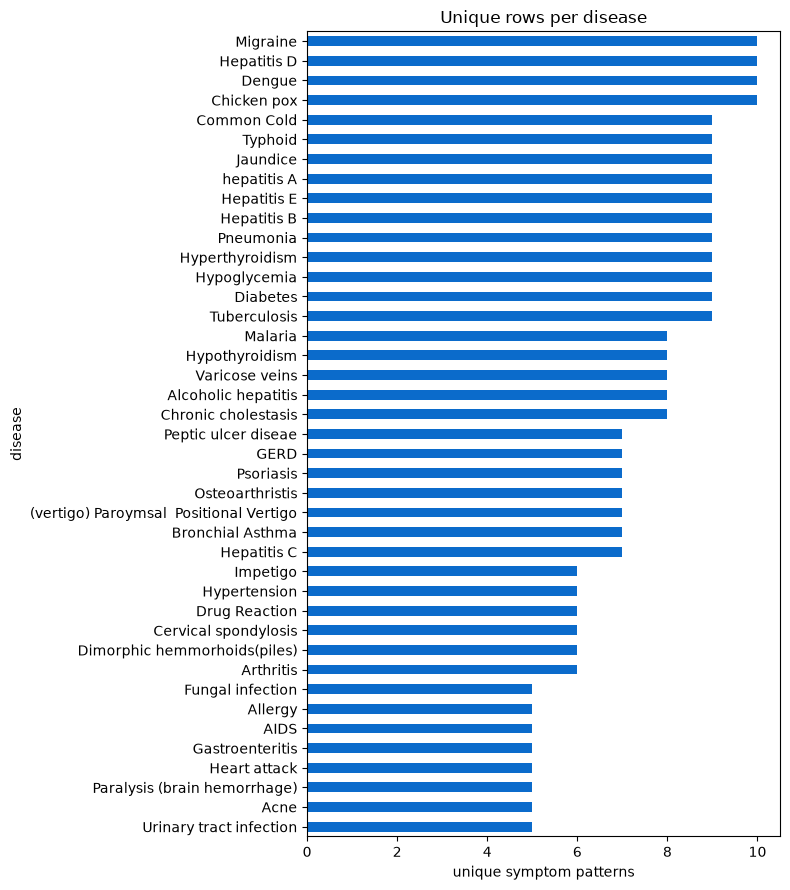

In [8]:
counts = unique["disease"].value_counts().sort_values()
fig, ax = plt.subplots(figsize=(8, 9))
counts.plot.barh(ax=ax, color="#0b6bcb")
ax.set_xlabel("unique symptom patterns"); ax.set_title("Unique rows per disease")
plt.tight_layout(); plt.show()

## 7 · Symptom statistics

count    304.00
mean       7.65
std        3.60
min        3.00
25%        5.00
50%        7.00
75%       10.00
max       17.00


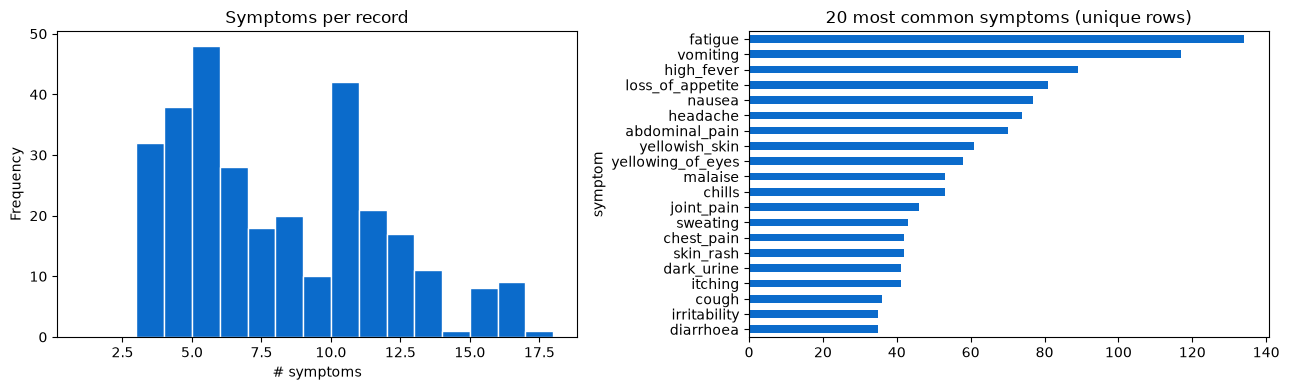

symptoms seen only once: 0 of 131


In [9]:
per_row = unique["symptoms"].apply(len)
print(per_row.describe().round(2).to_string())
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
per_row.plot.hist(bins=range(1, 19), ax=axes[0], color="#0b6bcb", edgecolor="white")
axes[0].set_title("Symptoms per record"); axes[0].set_xlabel("# symptoms")
freq = long["symptom"].value_counts()
freq.head(20).sort_values().plot.barh(ax=axes[1], color="#0b6bcb")
axes[1].set_title("20 most common symptoms (unique rows)")
plt.tight_layout(); plt.show()
print("symptoms seen only once:", int((freq == 1).sum()), "of", len(freq))

In [10]:
# The most 'diagnostic' symptoms: appear in the fewest diseases
spread = long.groupby("symptom")["disease"].nunique().sort_values()
print("symptoms specific to ONE disease:", int((spread == 1).sum()))
print("symptoms shared by 10+ diseases :", int((spread >= 10).sum()))
spread.tail(10)

symptoms specific to ONE disease: 80
symptoms shared by 10+ diseases : 6


symptom
chills                7
yellowing_of_eyes     7
yellowish_skin        8
abdominal_pain        9
nausea               10
loss_of_appetite     10
headache             10
high_fever           12
fatigue              17
vomiting             17
Name: disease, dtype: int64

## 8 · Severity weights file

In [11]:
severity["symptom_norm"] = severity["Symptom"].map(normalize_token)
ds_vocab = set(long["symptom"])
print("in dataset but no severity weight:", sorted(ds_vocab - set(severity["symptom_norm"])))
print("in severity file but never used  :", sorted(set(severity["symptom_norm"]) - ds_vocab))
print()
print(severity["weight"].describe().round(2).to_string())

in dataset but no severity weight: ['foul_smell_of_urine']
in severity file but never used  : ['foul_smell_ofurine', 'prognosis']

count    133.00
mean       4.23
std        1.32
min        1.00
25%        3.00
50%        4.00
75%        5.00
max        7.00


## 9 · Which diseases look alike?
High symptom overlap (Jaccard) between diseases explains why the model returns **ranked lists**
instead of one answer.

In [12]:
disease_syms = long.groupby("disease")["symptom"].apply(set)
names = list(disease_syms.index)
pairs = []
for i in range(len(names)):
    for j in range(i + 1, len(names)):
        a, b = disease_syms[names[i]], disease_syms[names[j]]
        pairs.append((len(a & b) / len(a | b), names[i], names[j]))
pd.DataFrame(sorted(pairs, reverse=True)[:10], columns=["jaccard", "disease_a", "disease_b"]).round(2)

,jaccard,disease_a,disease_b
0,0.69,Hepatitis D,Hepatitis E
1,0.67,Hepatitis D,hepatitis A
2,0.60,Chronic cholestasis,Hepatitis D
3,0.50,Pneumonia,Tuberculosis
4,0.50,Hepatitis E,hepatitis A
5,0.50,Hepatitis C,Hepatitis D
6,0.50,Chronic cholestasis,hepatitis A
7,0.46,Malaria,Typhoid
8,0.44,Chronic cholestasis,Hepatitis C
9,0.43,Chronic cholestasis,Hepatitis E


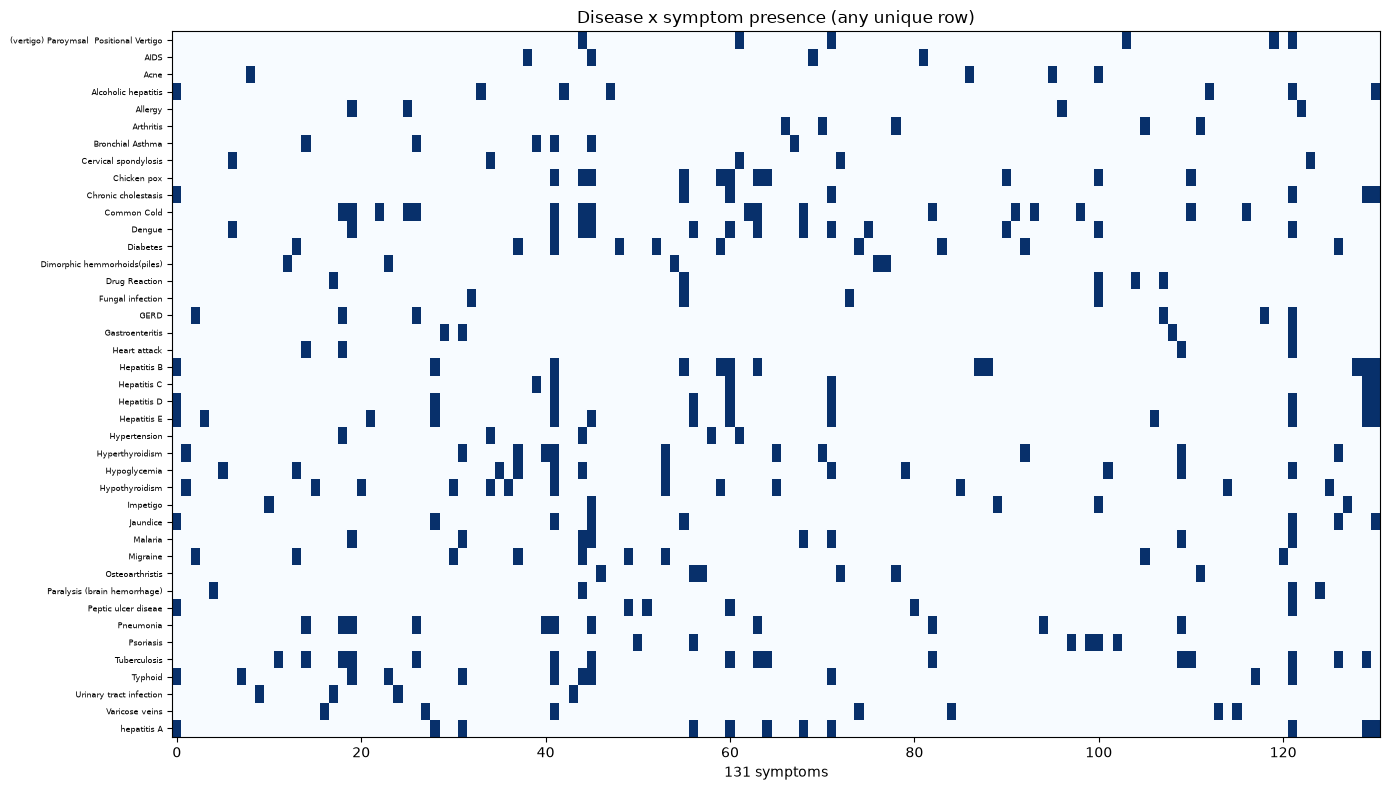

In [13]:
matrix = pd.crosstab(long["disease"], long["symptom"]).clip(upper=1)
fig, ax = plt.subplots(figsize=(14, 8))
ax.imshow(matrix.values, aspect="auto", cmap="Blues")
ax.set_yticks(range(len(matrix.index))); ax.set_yticklabels(matrix.index, fontsize=6)
ax.set_xlabel(f"{matrix.shape[1]} symptoms"); ax.set_title("Disease x symptom presence (any unique row)")
plt.tight_layout(); plt.show()

## 10 · Why we de-duplicate *before* splitting (data leakage)
If we split the raw 4,920 rows at random, the same symptom pattern lands in both train and test, so
the test score is inflated.

In [14]:
rng = np.random.default_rng(42)
def leak_rate(df, test_frac=0.2):
    idx = rng.permutation(len(df)); cut = int(len(df) * (1 - test_frac))
    tr = set(zip(df.iloc[idx[:cut]]["disease"], df.iloc[idx[:cut]]["symptoms"]))
    te = list(zip(df.iloc[idx[cut:]]["disease"], df.iloc[idx[cut:]]["symptoms"]))
    return float(np.mean([t in tr for t in te]))

print(f"raw split    : {leak_rate(records):.1%} of test rows also appear in train")
print(f"dedupe first : {leak_rate(unique):.1%} of test rows also appear in train")

raw split    : 100.0% of test rows also appear in train
dedupe first : 0.0% of test rows also appear in train


## 11 · Why we augment with symptom subsets
Training rows list many symptoms, but real users usually type 2–4. We simulate this by randomly
dropping symptoms from training rows, otherwise the model never sees partial inputs.

In [15]:
print("median symptoms in a training row:", per_row.median())
example = list(unique.loc[unique["symptoms"].apply(len) >= 6, "symptoms"].iloc[0])
print("full record :", example)
for _ in range(3):
    k = int(rng.integers(1, len(example) + 1))
    print(f"subset (k={k}):", sorted(rng.choice(example, size=k, replace=False).tolist()))

median symptoms in a training row: 7.0
full record : ['acidity', 'chest_pain', 'cough', 'stomach_pain', 'ulcers_on_tongue', 'vomiting']
subset (k=4): ['chest_pain', 'cough', 'ulcers_on_tongue', 'vomiting']
subset (k=5): ['chest_pain', 'cough', 'stomach_pain', 'ulcers_on_tongue', 'vomiting']
subset (k=4): ['acidity', 'chest_pain', 'stomach_pain', 'ulcers_on_tongue']
